# Engineering Materials: Property Analysis and `Use` Classification

**Objective.** (1) Describe the mechanical and physical properties of 1,552 engineering materials,
(2) check the data against basic elasticity theory, and (3) build and evaluate classifiers that predict
the binary `Use` flag from material properties.

**Dataset (`data/material.csv`).**

| Column | Meaning | Unit |
|---|---|---|
| `Material` | Standard + designation + heat treatment (e.g. *ANSI Steel SAE 1015 annealed*) | – |
| `Su` | Ultimate tensile strength | MPa |
| `Sy` | Yield strength | MPa |
| `E` | Young's (elastic) modulus | MPa |
| `G` | Shear modulus | MPa |
| `mu` | Poisson's ratio ν | – |
| `Ro` | Density ρ | kg/m³ |
| `Use` | Target: whether the material is flagged as suitable for the (unspecified) application | bool |


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             classification_report)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

## 2. Data audit and cleaning

Before any modelling, check the raw data for missing values, duplicates and **physical consistency**:

* yield strength cannot exceed ultimate strength (`Sy ≤ Su`);
* for isotropic materials `G = E / (2(1 + ν))`, so the ratio of the recorded `G` to that theoretical value should be about 1.

In [2]:
raw = pd.read_csv("./data/material.csv")
print("shape:", raw.shape)
print("\nmissing values per column:\n", raw.isna().sum().to_string())
print("\nexact duplicate rows:", raw.duplicated().sum())
print("duplicate material names:", raw["Material"].duplicated().sum())
raw.describe().T

shape: (1552, 8)

missing values per column:
 Material    0
Su          0
Sy          0
E           0
G           0
mu          0
Ro          0
Use         0

exact duplicate rows: 4
duplicate material names: 92


,count,mean,std,min,25%,50%,75%,max
Su,1552.0,572.753,326.835,69.0,340.0,500.0,705.00,2220.00
Sy,1552.0,387.010,289.482,28.0,205.0,305.0,470.00,2048.00
E,1552.0,164571.521,56135.406,73000.0,105000.0,206000.0,206000.00,219000.00
G,1552.0,85598.840,125326.800,26000.0,40000.0,79000.0,80000.00,769000.00
mu,1552.0,0.303,0.025,0.2,0.3,0.3,0.32,0.35
Ro,1552.0,6929.843,2115.172,1750.0,7160.0,7860.0,7860.00,8930.00


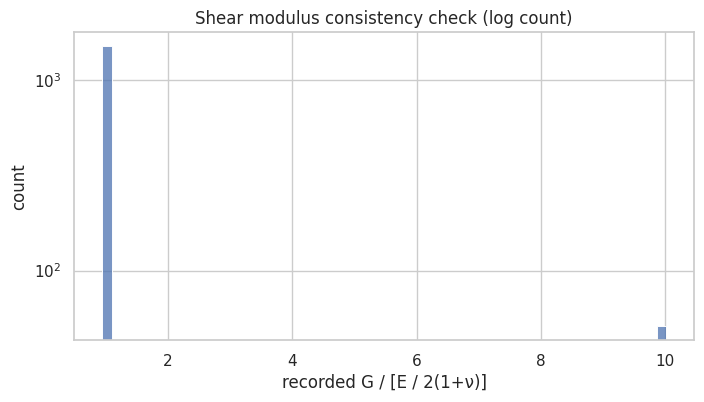

rows with G about 10x too large: 51


,Material,E,G,mu,G_ratio
109,ANSI Steel SAE 30201 annealed,193000,743000,0.3,10.009
110,ANSI Steel SAE 30201 1/4-hard,193000,743000,0.3,10.009
111,ANSI Steel SAE 30201 1/2-hard,193000,743000,0.3,10.009
112,ANSI Steel SAE 30201 3/4-hard,193000,743000,0.3,10.009
113,ANSI Steel SAE 30201 Full-hard,193000,743000,0.3,10.009


rows with Sy > Su (physically impossible): 4


,Material,Su,Sy,Use
300,ANSI Copper Alloy C51100,317,345,False
327,ANSI Copper Alloy C70400,262,276,False
625,ISO EN FeP01,270,280,False
718,DIN DIN St1203,270,280,False


In [3]:
G_theory = raw["E"] / (2 * (1 + raw["mu"]))
raw["G_ratio"] = raw["G"] / G_theory

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(raw["G_ratio"], bins=60, ax=ax)
ax.set(xlabel="recorded G / [E / 2(1+ν)]", ylabel="count", yscale="log",
       title="Shear modulus consistency check (log count)")
plt.show()

g_err = raw["G_ratio"] > 5
print(f"rows with G about 10x too large: {g_err.sum()}")
display(raw.loc[g_err, ["Material", "E", "G", "mu", "G_ratio"]].head())
print(f"rows with Sy > Su (physically impossible): {(raw['Sy'] > raw['Su']).sum()}")
display(raw.loc[raw["Sy"] > raw["Su"], ["Material", "Su", "Sy", "Use"]])

**Findings.**

* No missing values.
* A few rows are exact duplicates. Each one would count twice and could appear in both the training and test sets, so they are removed.
* **51 rows (the ANSI 30xxx austenitic stainless steels) have G = 743,000 MPa.** This is ten times the physically correct value
  (≈ 74,300 MPa, which matches E/(2(1+ν)) for E = 193 GPa and ν = 0.3). It is a decimal-place entry error, and it caused the
  inflated `G` standard deviation (125 GPa, larger than the mean) in the original summary. It is corrected by dividing by 10.
* A few rows have `Sy > Su`, which is physically impossible and most likely transposed values. We cannot know which number is correct, so these rows are dropped.

In [4]:
df = raw.drop_duplicates(subset=["Material", "Su", "Sy", "E", "G", "mu", "Ro", "Use"]).copy()
df.loc[df["G_ratio"] > 5, "G"] = df.loc[df["G_ratio"] > 5, "G"] / 10
df = df[df["Sy"] <= df["Su"]].drop(columns="G_ratio").reset_index(drop=True)

# Material family (first two words of the name), used for EDA only
df["family"] = df["Material"].str.split().str[:2].str.join(" ")

print(f"rows: {len(raw)} raw -> {len(df)} clean")
recheck = (df["G"] / (df["E"] / (2 * (1 + df["mu"])))).describe()
print("G ratio after correction:\n", recheck[["min", "50%", "max"]].round(3).to_string())
df.describe().T

rows: 1552 raw -> 1544 clean
G ratio after correction:
 min    0.947
50%    1.001
max    1.016


,count,mean,std,min,25%,50%,75%,max
Su,1544.0,573.377,327.296,69.0,340.00,500.0,705.50,2220.00
Sy,1544.0,387.344,290.128,28.0,203.75,305.0,470.50,2048.00
E,1544.0,164487.694,56180.432,73000.0,105000.00,206000.0,206000.00,219000.00
G,1544.0,63258.355,22537.391,26000.0,40000.00,79000.0,80000.00,85000.00
mu,1544.0,0.303,0.025,0.2,0.30,0.3,0.32,0.35
Ro,1544.0,6923.806,2118.776,1750.0,7160.00,7860.0,7860.00,8930.00


## 3. Exploratory data analysis

### 3.1 Target balance

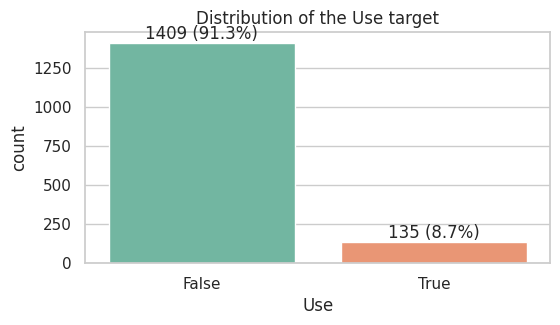

In [5]:
counts = df["Use"].value_counts()
fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax, palette="Set2", hue=counts.index.astype(str), legend=False)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v} ({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set(xlabel="Use", ylabel="count", title="Distribution of the Use target")
plt.show()

The target is **highly imbalanced**: about 9% of rows are `True`. A model that always predicts `False` already
scores about 91% accuracy. **Accuracy alone is therefore misleading.** This explains the SVM result in the
previous version of this notebook: it reached 91.6% accuracy by predicting `False` for every row, which is also why sklearn
warned about undefined precision. Below, models are compared with balanced accuracy, F1 for the positive class, ROC-AUC
and average precision (PR-AUC), and always against a majority-class baseline.

### 3.2 Distributions by class

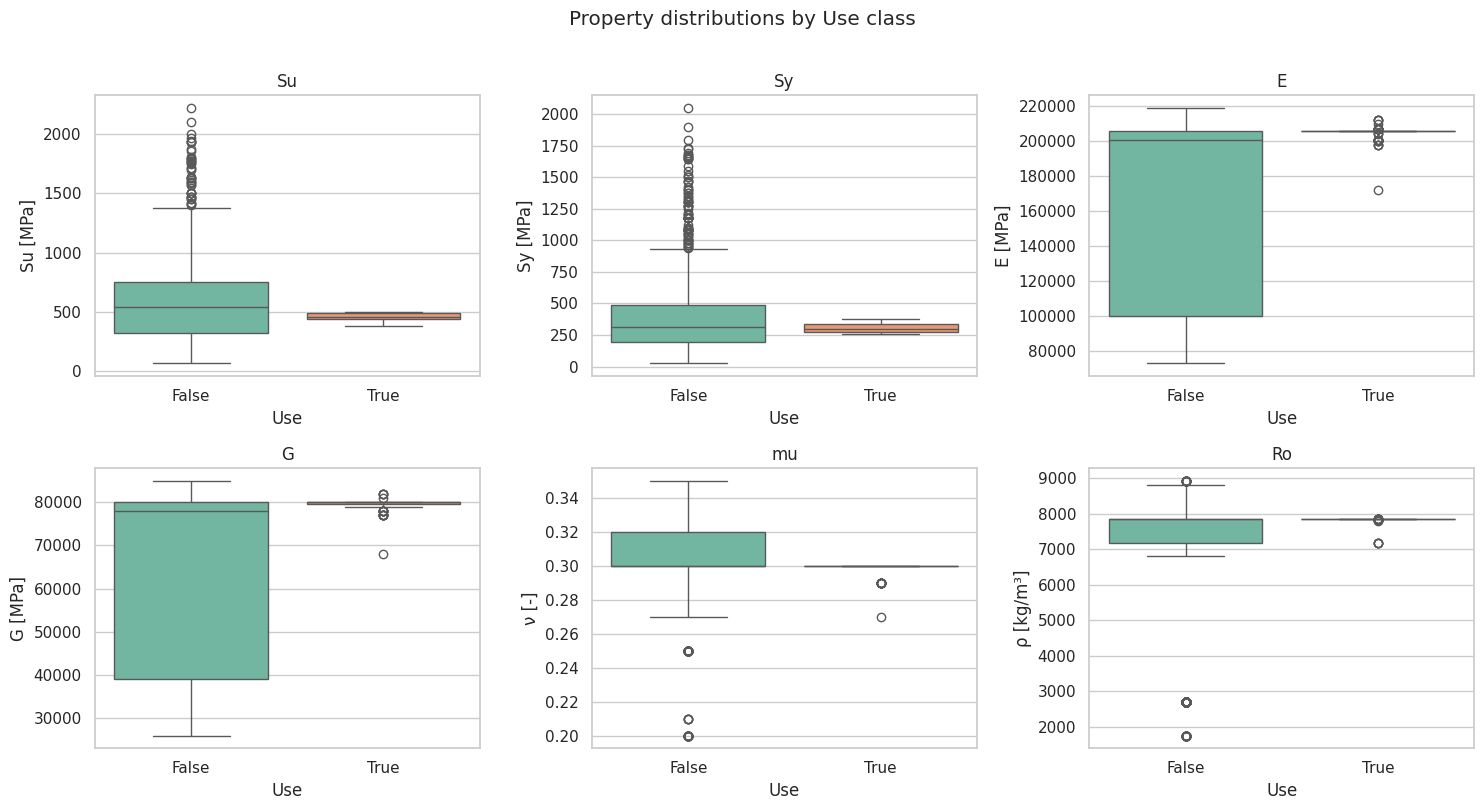

Use            False      True 
Su min         69.00     380.00
   median     540.00     460.00
   max       2220.00     503.00
Sy min         28.00     255.00
   median     315.00     295.00
   max       2048.00     375.00
E  min      73000.00  172000.00
   median  201000.00  206000.00
   max     219000.00  212000.00
G  min      26000.00   68000.00
   median   78000.00   80000.00
   max      85000.00   82000.00
mu min          0.20       0.27
   median       0.30       0.30
   max          0.35       0.30
Ro min       1750.00    7160.00
   median    7860.00    7860.00
   max       8930.00    7860.00

In [6]:
features = ["Su", "Sy", "E", "G", "mu", "Ro"]
labels = {"Su": "Su [MPa]", "Sy": "Sy [MPa]", "E": "E [MPa]", "G": "G [MPa]", "mu": "ν [-]", "Ro": "ρ [kg/m³]"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="Use", y=f, ax=ax, palette="Set2", hue="Use", legend=False)
    ax.set(ylabel=labels[f], title=f)
fig.suptitle("Property distributions by Use class", y=1.01)
plt.tight_layout()
plt.show()

df.groupby("Use")[features].agg(["min", "median", "max"]).T

The `True` class lies inside a **very narrow property window**: Su ≈ 380–503 MPa, Sy ≈ 255–375 MPa,
E ≥ 172 GPa and ρ ≈ 7,160–7,860 kg/m³. In practice these are low-to-medium-strength ferrous alloys (structural / mild steels).
The `False` class covers the full range, including aluminium, copper and magnesium alloys and high-strength steels.

### 3.3 Strength relationships

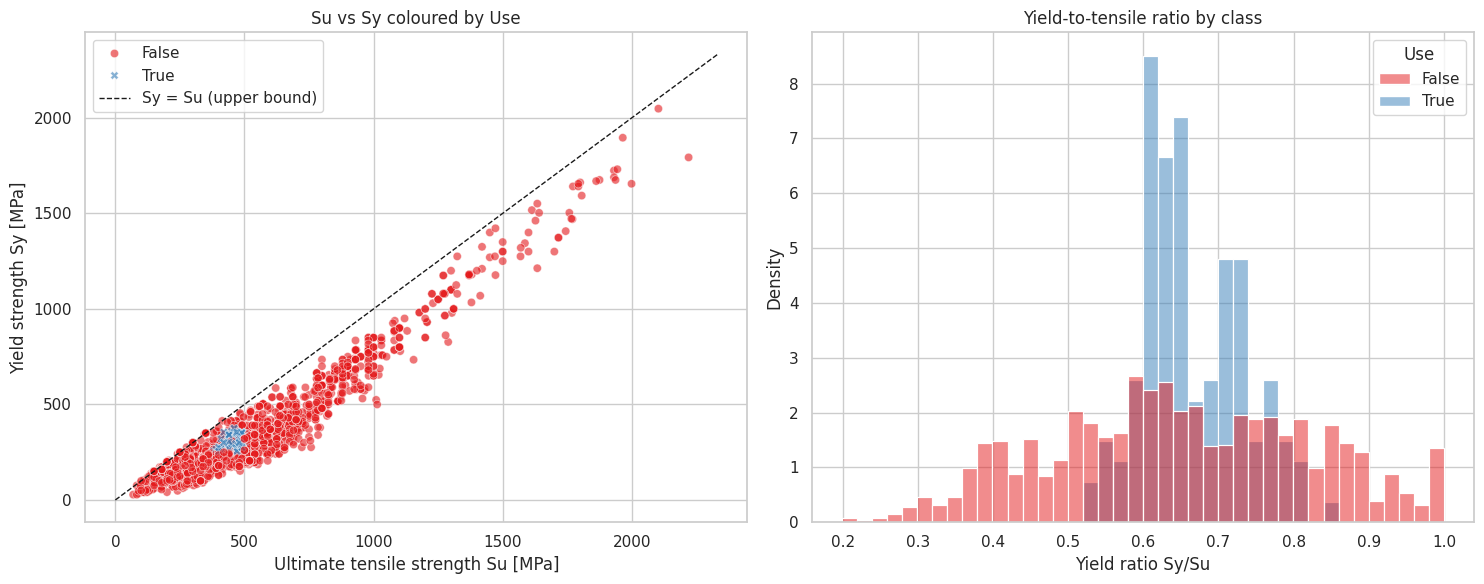

Pearson r(Su, Sy) = 0.958;  linear fit Sy = 0.849*Su + -99.4 MPa
median yield ratio: 0.64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=df, x="Su", y="Sy", hue="Use", style="Use", alpha=0.6, ax=axes[0], palette="Set1")
lim = [0, df["Su"].max() * 1.05]
axes[0].plot(lim, lim, "k--", lw=1, label="Sy = Su (upper bound)")
axes[0].set(xlabel="Ultimate tensile strength Su [MPa]", ylabel="Yield strength Sy [MPa]",
            title="Su vs Sy coloured by Use")
axes[0].legend()

df["Sy_Su"] = df["Sy"] / df["Su"]
sns.histplot(data=df, x="Sy_Su", hue="Use", bins=40, stat="density", common_norm=False, ax=axes[1], palette="Set1")
axes[1].set(xlabel="Yield ratio Sy/Su", title="Yield-to-tensile ratio by class")
plt.tight_layout()
plt.show()

r = df[["Su", "Sy"]].corr().iloc[0, 1]
slope, intercept = np.polyfit(df["Su"], df["Sy"], 1)
print(f"Pearson r(Su, Sy) = {r:.3f};  linear fit Sy = {slope:.3f}*Su + {intercept:.1f} MPa")
print(f"median yield ratio: {df['Sy_Su'].median():.2f}")

*(The original line plot of Sy against Su joined points in sorted-Su order, which shows a noisy band rather than the
relationship. A scatter plot is the right chart for paired observations.)* Su and Sy are strongly and linearly
correlated, and every point now lies below the `Sy = Su` bound after cleaning. The `True` materials form a small cluster in the lower-left part of the main band.

### 3.4 Stiffness vs strength and material families

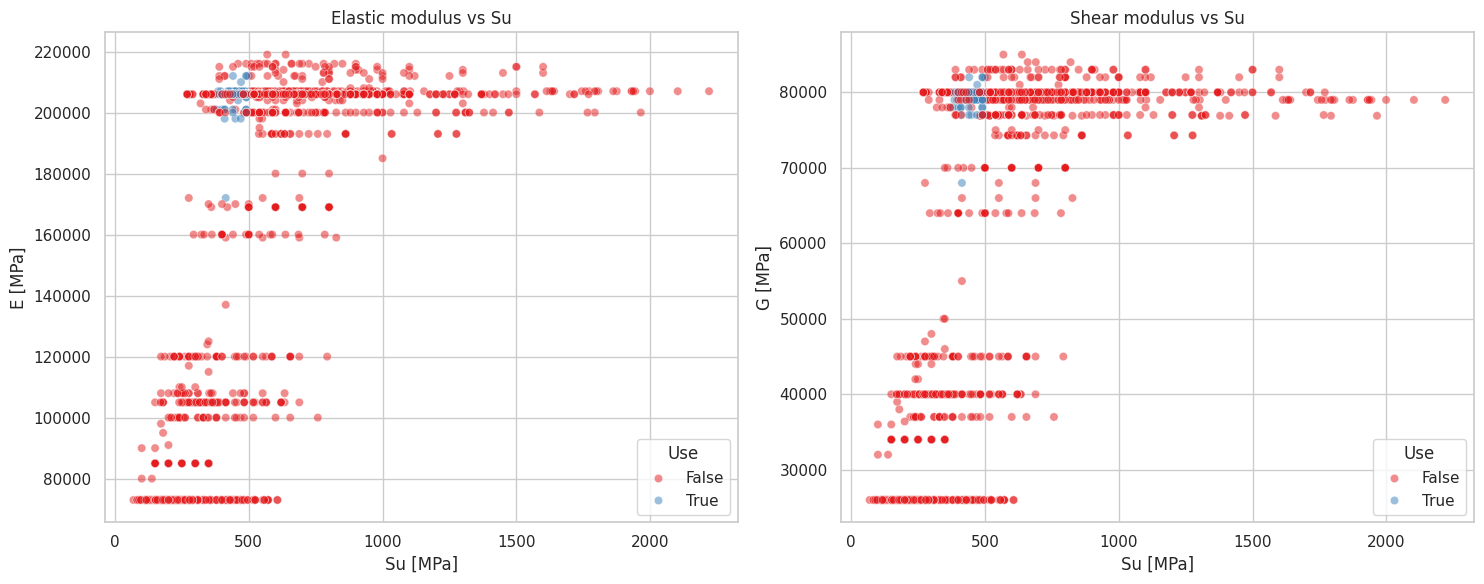

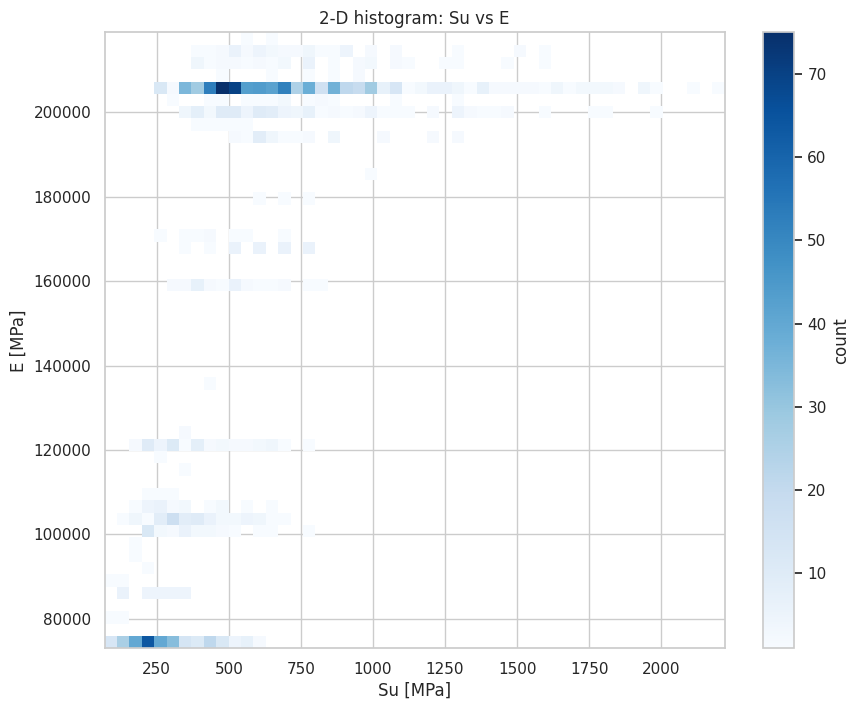

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=df, x="Su", y="E", hue="Use", alpha=0.5, ax=axes[0], palette="Set1")
axes[0].set(xlabel="Su [MPa]", ylabel="E [MPa]", title="Elastic modulus vs Su")
sns.scatterplot(data=df, x="Su", y="G", hue="Use", alpha=0.5, ax=axes[1], palette="Set1")
axes[1].set(xlabel="Su [MPa]", ylabel="G [MPa]", title="Shear modulus vs Su")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
h = ax.hist2d(df["Su"], df["E"], bins=(50, 50), cmap="Blues", cmin=1)
fig.colorbar(h[3], ax=ax, label="count")
ax.set(xlabel="Su [MPa]", ylabel="E [MPa]", title="2-D histogram: Su vs E")
plt.show()

Stiffness does not follow strength: E and G are set by the **base metal** and appear as horizontal bands
(Mg ≈ 45 GPa, Al ≈ 70 GPa, Cu ≈ 100–120 GPa, cast iron ≈ 100–170 GPa, steel ≈ 190–210 GPa). Heat treatment and alloying
change strength a great deal but stiffness hardly at all, which is expected from materials science. The 2-D histogram
shows that most rows are steels near 206 GPa.

In [9]:
fam = (df.groupby("family")["Use"].agg(n="size", n_use="sum", share="mean")
         .sort_values("n", ascending=False).head(15))
fam

,n,n_use,share
family,,,
GOST Steel,294,27,0.092
ANSI Aluminum,251,0,0.000
CSN CSN,172,24,0.140
ANSI Steel,160,15,0.094
DIN DIN,113,22,0.195
ISO EN,79,20,0.253
NF NF,76,12,0.158
ANSI Copper,75,0,0.000
BS BS,61,7,0.115


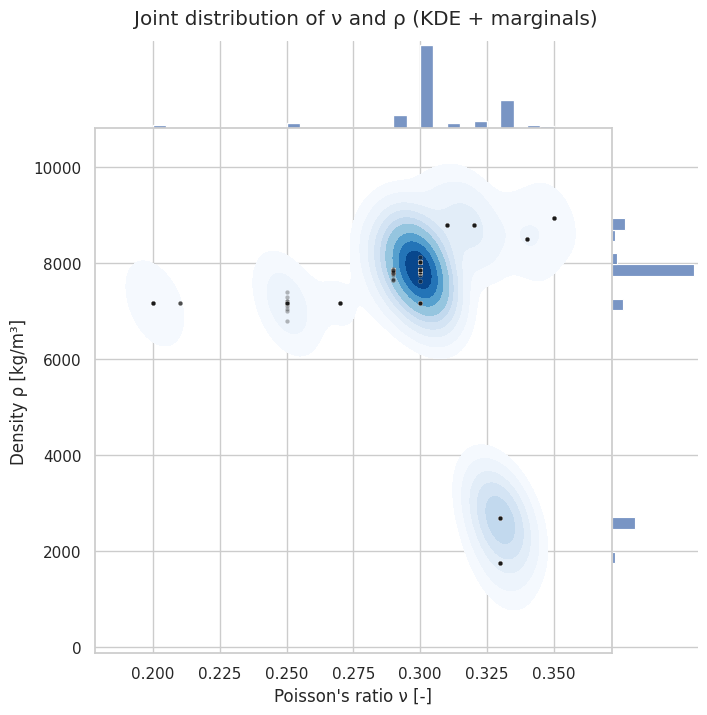

In [10]:
g = sns.JointGrid(data=df, x="mu", y="Ro", height=7, space=0, ratio=6)
g.plot_joint(sns.kdeplot, fill=True, cmap="Blues", warn_singular=False)
g.plot_joint(sns.scatterplot, s=10, color="k", alpha=0.3)
g.plot_marginals(sns.histplot, bins=30)
g.set_axis_labels("Poisson's ratio ν [-]", "Density ρ [kg/m³]")
g.figure.suptitle("Joint distribution of ν and ρ (KDE + marginals)", y=1.02)
plt.show()

*(Fixed from the original: the x-axis was labelled "Elastic Modulus (E)" although it plotted `mu`, and the deprecated
`shade=` argument caused an error.)* ν and ρ take only a few distinct values that cluster by base metal, for example
Al (ν = 0.33, ρ = 2,700), steel (0.30, 7,860) and Cu (0.34–0.35, 8,500–8,930). Many property values in this dataset are
handbook values for the whole alloy class, not measurements of each grade.

### 3.5 Correlation structure

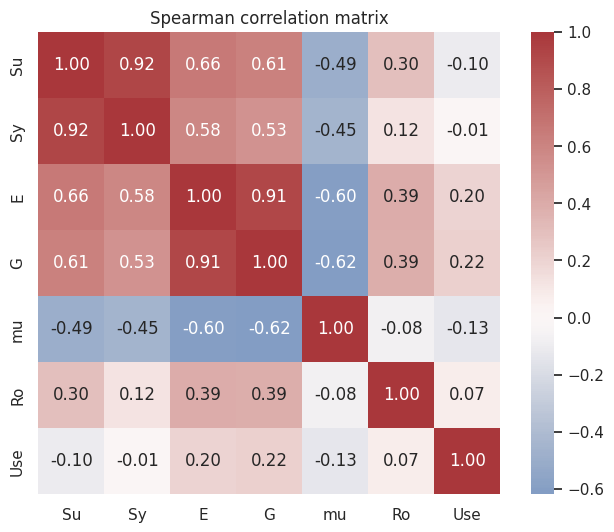

In [11]:
corr = df[features + ["Use"]].astype(float).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Spearman correlation matrix")
plt.show()

E, G and ρ are strongly correlated with each other because all three are fixed by the base metal. Su and Sy form a second
correlated pair. The **monotonic** correlation of `Use` with any single feature is weak, because `Use` is defined by a
*window* (intermediate values of strength), not by a threshold. This is why linear models do poorly in Section 5.

## 4. Elasticity theory check

Within the linear-elastic region, Hooke's law gives σ = E·ε (tension) and τ = G·γ (shear). For isotropic
materials the constants are linked by **G = E / (2(1 + ν))**. The illustrative example in the original notebook used strains up to 100%,
which is far outside the elastic range of metals (yield strain ≈ 0.1–0.5%). Below, each curve uses the dataset's own median
properties for steel and aluminium and stops at the yield point.

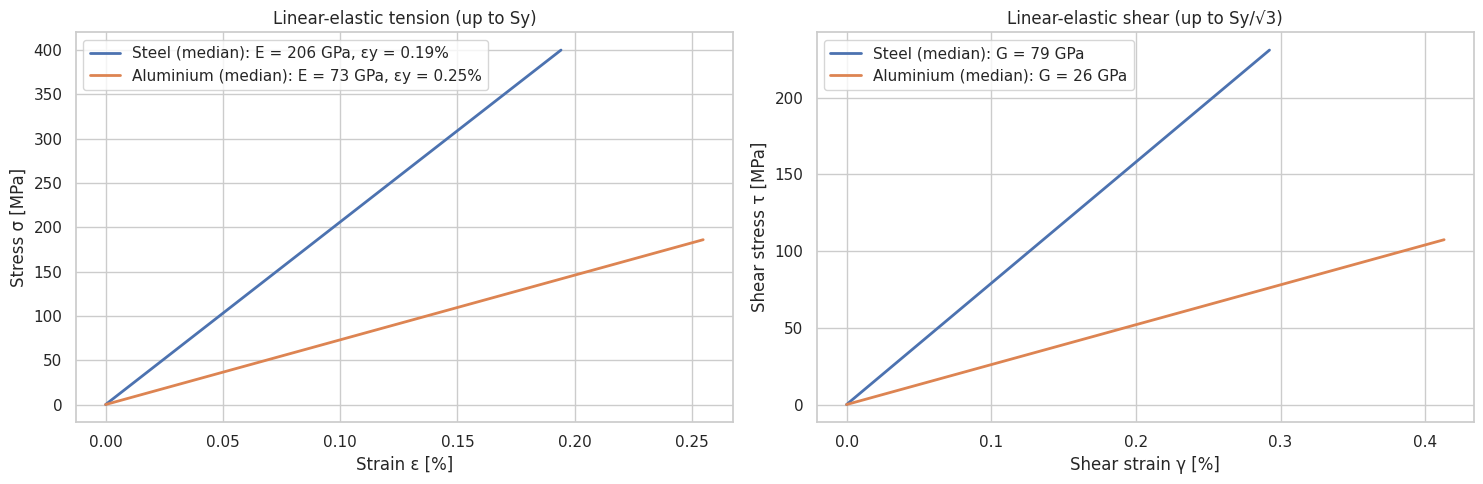

In [12]:
reps = {
    "Steel (median)": df[df["family"].str.contains("Steel")][features].median(),
    "Aluminium (median)": df[df["family"].str.contains("Aluminum")][features].median(),
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, p in reps.items():
    eps_y = p["Sy"] / p["E"]                     # yield strain
    eps = np.linspace(0, eps_y, 50)
    axes[0].plot(eps * 100, p["E"] * eps, lw=2, label=f"{name}: E = {p['E']/1e3:.0f} GPa, εy = {eps_y*100:.2f}%")
    tau_y = p["Sy"] / np.sqrt(3)                 # von Mises shear yield
    gam = np.linspace(0, tau_y / p["G"], 50)
    axes[1].plot(gam * 100, p["G"] * gam, lw=2, label=f"{name}: G = {p['G']/1e3:.0f} GPa")
axes[0].set(xlabel="Strain ε [%]", ylabel="Stress σ [MPa]", title="Linear-elastic tension (up to Sy)")
axes[1].set(xlabel="Shear strain γ [%]", ylabel="Shear stress τ [MPa]", title="Linear-elastic shear (up to Sy/√3)")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

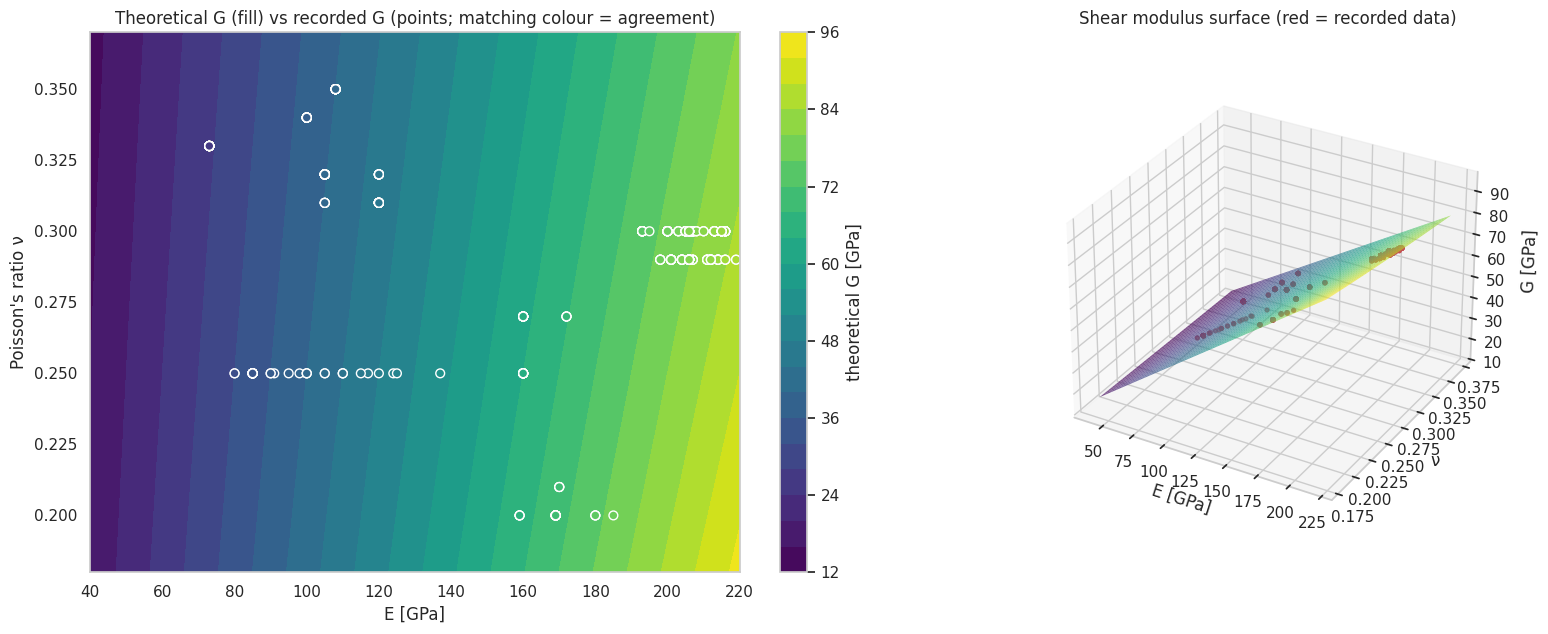

G residual vs theory (MPa): mean = -63, MAE = 658, max |res| = 1444;  MAPE = 1.57%


In [13]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers 3-D projection)

E_grid, nu_grid = np.meshgrid(np.linspace(40e3, 220e3, 120), np.linspace(0.18, 0.37, 120))   # MPa, -
G_grid = E_grid / (2 * (1 + nu_grid))

fig = plt.figure(figsize=(17, 6.5))
ax1 = fig.add_subplot(1, 2, 1)
cf = ax1.contourf(E_grid / 1e3, nu_grid, G_grid / 1e3, levels=20, cmap="viridis")
fig.colorbar(cf, ax=ax1, label="theoretical G [GPa]")
sc = ax1.scatter(df["E"] / 1e3, df["mu"], c=df["G"] / 1e3, cmap="viridis", edgecolor="w", s=40,
                 vmin=cf.get_clim()[0], vmax=cf.get_clim()[1])
ax1.set(xlabel="E [GPa]", ylabel="Poisson's ratio ν",
        title="Theoretical G (fill) vs recorded G (points; matching colour = agreement)")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
surf = ax2.plot_surface(E_grid / 1e3, nu_grid, G_grid / 1e3, cmap="viridis", alpha=0.7, linewidth=0)
ax2.scatter(df["E"] / 1e3, df["mu"], df["G"] / 1e3, color="r", s=8)
ax2.set(xlabel="E [GPa]", ylabel="ν", title="Shear modulus surface (red = recorded data)")
ax2.set_zlabel("G [GPa]", labelpad=8)
ax2.set_box_aspect(None, zoom=0.85)
plt.tight_layout()
plt.show()

resid = df["G"] - df["E"] / (2 * (1 + df["mu"]))
print(f"G residual vs theory (MPa): mean = {resid.mean():.0f}, MAE = {resid.abs().mean():.0f}, "
      f"max |res| = {resid.abs().max():.0f};  MAPE = {(resid.abs() / df['G']).mean():.2%}")

After the G correction, the recorded data agree closely with isotropic elasticity theory. Points sit on the
surface, and the remaining deviations are a few percent, which is normal rounding in handbook values. This supports
the data-cleaning step and shows that `G` is almost entirely redundant given `E` and ν. *(The original 3-D cell used the removed
`fig.gca(projection='3d')` API and failed; it is replaced here by one working cell.)*

## 5. Modelling

### 5.1 Design decisions

* **Features: the six numeric properties only.** The previous version label-encoded the `Material` *name* and used
  it as a feature. That is methodologically wrong: almost every name is unique (≈ 1,460 of 1,552), so the code is
  an arbitrary row ID with alphabetical ordering and carries no physical meaning. It would only let the model memorise
  near-duplicate entries. It is removed.
* **Stratified 80/20 split** so that the test set keeps the ~9% positive rate.
* **Feature scaling inside a `Pipeline`.** SVM (RBF kernel) and KNN depend on distances. Without scaling, `E` (~10⁵)
  dominates `mu` (~10⁻¹) entirely. This was the main reason the original SVM collapsed to predicting the majority class.
  Putting the scaler in the pipeline also stops test-set statistics leaking into training.
* **Class imbalance** is handled with `class_weight="balanced"` where the model supports it.
* **Model selection by 5-fold stratified cross-validation** on the training set only. The test set is used once, at the end.

In [14]:
X = df[features]
y = df["Use"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train: {X_train.shape}, positive rate {y_train.mean():.3f}")
print(f"test : {X_test.shape}, positive rate {y_test.mean():.3f}")

train: (1235, 6), positive rate 0.087
test : (309, 6), positive rate 0.087


### 5.2 Hyperparameter tuning (CV on the training set)

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

svm_search = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED)),
    {"svc__C": [0.1, 1, 10, 100, 1000], "svc__gamma": ["scale", 0.1, 1, 10]},
    scoring="average_precision", cv=cv, n_jobs=-1).fit(X_train, y_train)

knn_search = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15],
     "kneighborsclassifier__weights": ["uniform", "distance"]},
    scoring="average_precision", cv=cv, n_jobs=-1).fit(X_train, y_train)

print("SVM best:", svm_search.best_params_, f"CV PR-AUC = {svm_search.best_score_:.3f}")
print("KNN best:", knn_search.best_params_, f"CV PR-AUC = {knn_search.best_score_:.3f}")

SVM best: {'svc__C': 1000, 'svc__gamma': 10} CV PR-AUC = 0.994
KNN best: {'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__weights': 'distance'} CV PR-AUC = 0.993


### 5.3 Cross-validated model comparison

In [16]:
models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "SVM unscaled (original setup)": SVC(probability=True, random_state=SEED),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    "SVM (scaled, tuned)": svm_search.best_estimator_,
    "KNN (scaled, tuned)": knn_search.best_estimator_,
    "Random forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
}
from sklearn.metrics import make_scorer
scoring = {"accuracy": "accuracy", "balanced_acc": "balanced_accuracy",
           "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

rows = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1, error_score="raise")
    rows[name] = {f"{k}": f"{res['test_' + k].mean():.3f} ± {res['test_' + k].std():.3f}" for k in scoring}
cv_table = pd.DataFrame(rows).T
cv_table

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
Baseline (majority),0.913 ± 0.002,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.087 ± 0.002
SVM unscaled (original setup),0.913 ± 0.002,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.832 ± 0.017,0.301 ± 0.045
Logistic regression,0.867 ± 0.017,0.927 ± 0.009,0.399 ± 0.034,1.000 ± 0.000,0.570 ± 0.034,0.935 ± 0.010,0.404 ± 0.040
"SVM (scaled, tuned)",0.994 ± 0.005,0.992 ± 0.010,0.941 ± 0.049,0.991 ± 0.018,0.965 ± 0.030,0.999 ± 0.001,0.994 ± 0.008
"KNN (scaled, tuned)",0.989 ± 0.006,0.982 ± 0.019,0.913 ± 0.038,0.972 ± 0.037,0.942 ± 0.033,0.999 ± 0.001,0.993 ± 0.008
Random forest,0.998 ± 0.003,0.999 ± 0.002,0.983 ± 0.035,1.000 ± 0.000,0.991 ± 0.018,1.000 ± 0.000,1.000 ± 0.000


**Reading the CV table.**

* The **baseline** reaches about 91% accuracy with F1 = 0. Any model has to beat it on balanced accuracy, F1 and PR-AUC, not on accuracy.
* The **unscaled SVM** (the original configuration) ties the baseline exactly on accuracy and has F1 = 0. Its ROC-AUC is
  above 0.5, so it does rank the samples, but the decision function never crosses the threshold. The original
  "91.6% accuracy" was therefore a null result.
* **Logistic regression** cannot represent the "window" shape of the positive class, so its precision is poor.
* **Scaled, tuned SVM and KNN** jump to F1 ≈ 0.94–0.97 and PR-AUC ≈ 0.99 once scaling is fixed. **Random forest** is the
  strongest and most stable (CV F1 ≈ 0.99). Its axis-aligned splits match the threshold-type rule that appears to define the
  label (Section 7).
* The best SVM parameters (C = 1000, γ = 10) sit at the edge of the grid, so a sharp, almost rule-like decision boundary is
  preferred. This is another sign of a deterministic label.

## 6. Final evaluation on the held-out test set

In [17]:
final = {k: models[k] for k in ["Baseline (majority)", "SVM unscaled (original setup)", "Logistic regression",
                                 "SVM (scaled, tuned)", "KNN (scaled, tuned)", "Random forest"]}
test_rows, probas, preds = {}, {}, {}
for name, model in final.items():
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    s = model.predict_proba(X_test)[:, 1]
    preds[name], probas[name] = p, s
    test_rows[name] = {
        "accuracy": accuracy_score(y_test, p),
        "balanced_acc": balanced_accuracy_score(y_test, p),
        "precision": precision_score(y_test, p, zero_division=0),
        "recall": recall_score(y_test, p),
        "f1": f1_score(y_test, p),
        "roc_auc": roc_auc_score(y_test, s),
        "pr_auc": average_precision_score(y_test, s),
    }
test_table = pd.DataFrame(test_rows).T.round(3)
test_table

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
Baseline (majority),0.913,0.500,0.000,0.000,0.000,0.500,0.087
SVM unscaled (original setup),0.913,0.500,0.000,0.000,0.000,0.804,0.296
Logistic regression,0.864,0.909,0.388,0.963,0.553,0.939,0.427
"SVM (scaled, tuned)",0.990,0.961,0.962,0.926,0.943,0.998,0.987
"KNN (scaled, tuned)",0.994,0.980,0.963,0.963,0.963,0.981,0.965
Random forest,0.997,0.981,1.000,0.963,0.981,0.980,0.966


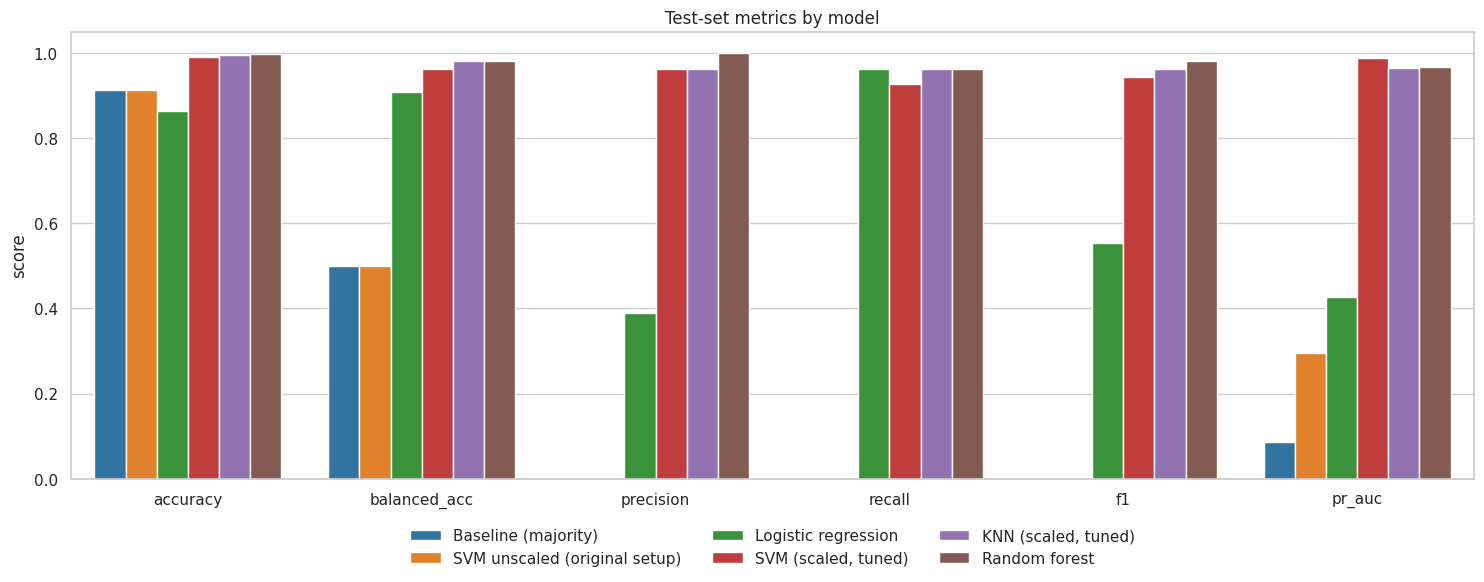

In [18]:
plot_metrics = ["accuracy", "balanced_acc", "precision", "recall", "f1", "pr_auc"]
long = test_table[plot_metrics].reset_index(names="model").melt(id_vars="model", var_name="metric", value_name="score")
fig, ax = plt.subplots(figsize=(15, 6))
sns.barplot(data=long, x="metric", y="score", hue="model", ax=ax, palette="tab10")
ax.set(ylim=(0, 1.05), ylabel="score", xlabel="", title="Test-set metrics by model")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

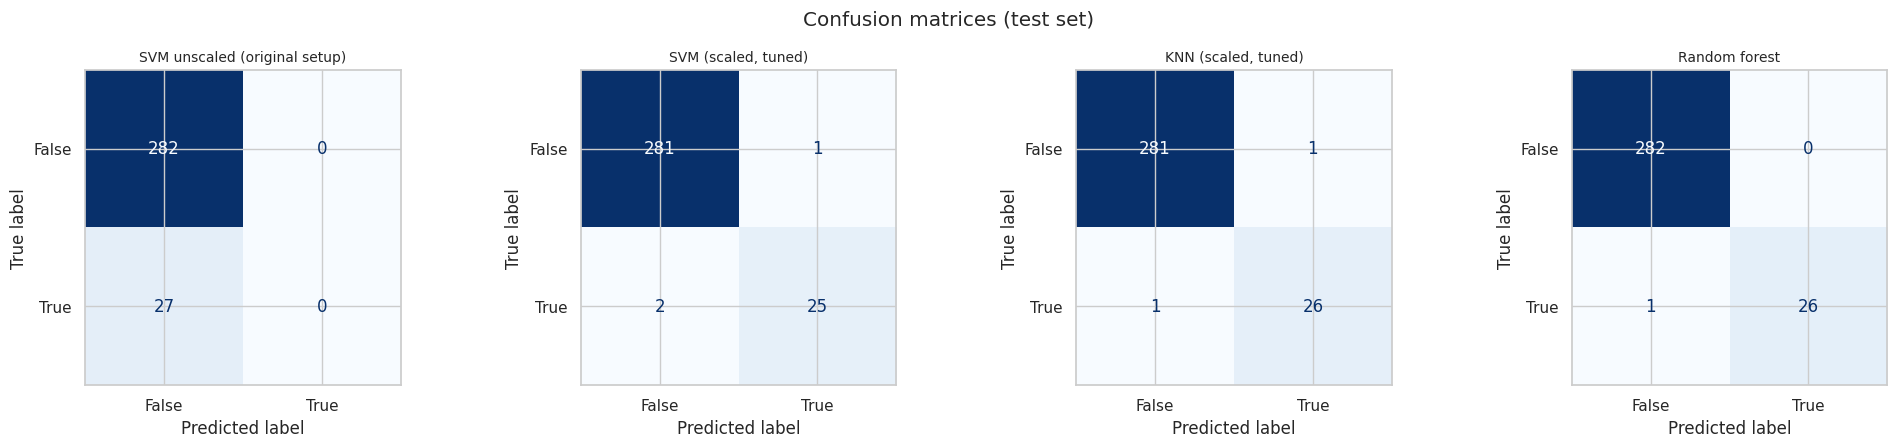

=== SVM (scaled, tuned) ===
              precision    recall  f1-score   support

       False      0.993     0.996     0.995       282
        True      0.962     0.926     0.943        27

    accuracy                          0.990       309
   macro avg      0.977     0.961     0.969       309
weighted avg      0.990     0.990     0.990       309

=== KNN (scaled, tuned) ===
              precision    recall  f1-score   support

       False      0.996     0.996     0.996       282
        True      0.963     0.963     0.963        27

    accuracy                          0.994       309
   macro avg      0.980     0.980     0.980       309
weighted avg      0.994     0.994     0.994       309

=== Random forest ===
              precision    recall  f1-score   support

       False      0.996     1.000     0.998       282
        True      1.000     0.963     0.981        27

    accuracy                          0.997       309
   macro avg      0.998     0.981     0.990       

In [19]:
show = ["SVM unscaled (original setup)", "SVM (scaled, tuned)", "KNN (scaled, tuned)", "Random forest"]
fig, axes = plt.subplots(1, len(show), figsize=(20, 4.5))
for ax, name in zip(axes, show):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]), display_labels=["False", "True"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10)
fig.suptitle("Confusion matrices (test set)")
plt.tight_layout()
plt.show()

for name in ["SVM (scaled, tuned)", "KNN (scaled, tuned)", "Random forest"]:
    print(f"=== {name} ===")
    print(classification_report(y_test, preds[name], target_names=["False", "True"], digits=3))

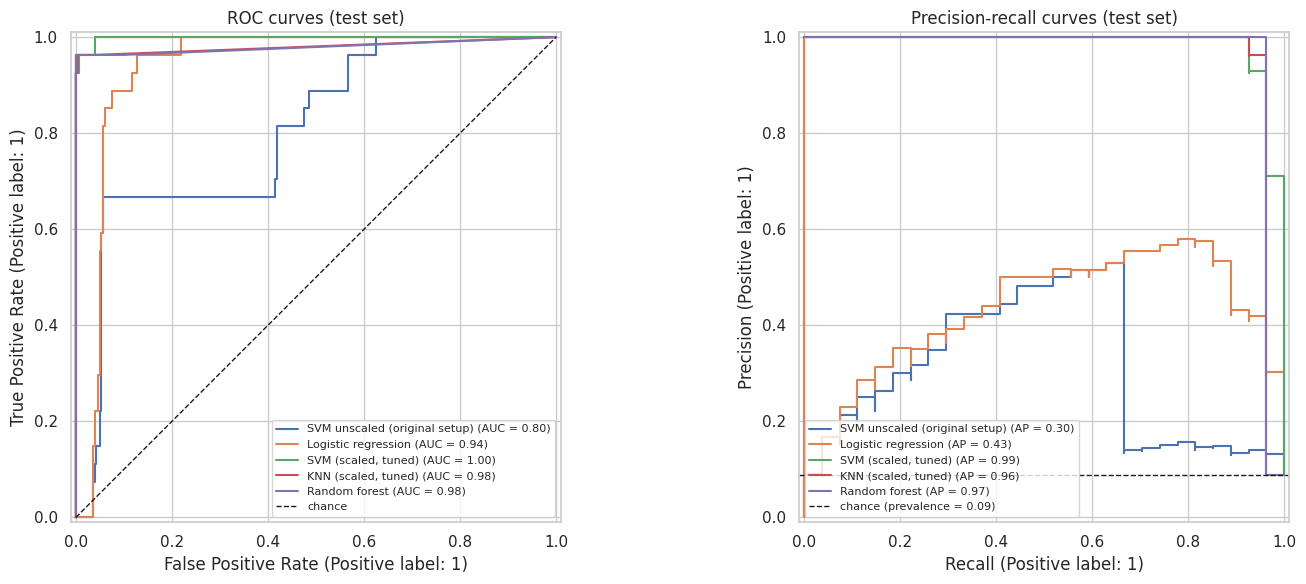

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name in final:
    if name.startswith("Baseline"):
        continue
    RocCurveDisplay.from_predictions(y_test, probas[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probas[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="chance")
axes[0].set_title("ROC curves (test set)")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"chance (prevalence = {y_test.mean():.2f})")
axes[1].set_title("Precision-recall curves (test set)")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=8)
plt.tight_layout()
plt.show()

For a minority class, the **precision-recall curve** is more informative than the ROC curve. ROC-AUC can look good even when
precision is poor, because the many true negatives keep the false-positive rate low. The test set contains only ≈ 27 positives,
so each misclassified positive changes recall by about 4 percentage points. Small differences between the top models are within sampling noise,
and the CV mean ± std in Section 5.3 is the more reliable comparison.

## 7. Interpretation: what drives `Use`?

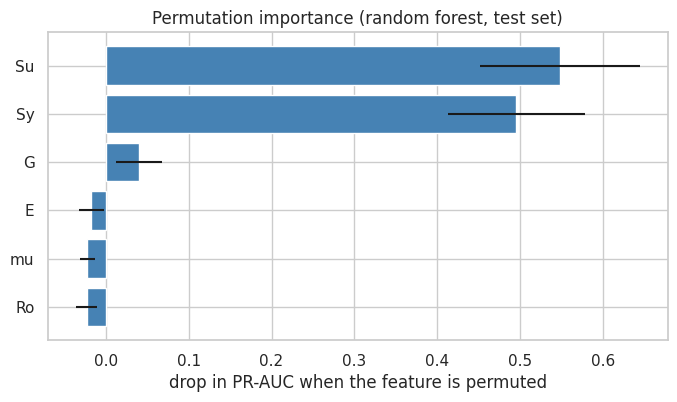

,importance,std
Su,0.548,0.096
Sy,0.495,0.083
G,0.040,0.028
E,-0.018,0.015
mu,-0.022,0.009
Ro,-0.023,0.013


In [21]:
rf = final["Random forest"]
pi = permutation_importance(rf, X_test, y_test, scoring="average_precision", n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=features).sort_values("importance")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp.index, imp["importance"], xerr=imp["std"], color="steelblue")
ax.set(xlabel="drop in PR-AUC when the feature is permuted", title="Permutation importance (random forest, test set)")
plt.show()
imp.sort_values("importance", ascending=False)

In [22]:
# A shallow, fully interpretable tree trained on the training set only
tree = DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(X_train, y_train)
print(export_text(tree, feature_names=features))
p_tree = tree.predict(X_test)
print(f"depth-4 tree on test: accuracy = {accuracy_score(y_test, p_tree):.3f}, "
      f"F1 = {f1_score(y_test, p_tree):.3f}, balanced acc = {balanced_accuracy_score(y_test, p_tree):.3f}")

|--- Su <= 506.50
|   |--- Sy <= 252.50
|   |   |--- class: 0
|   |--- Sy >  252.50
|   |   |--- G <= 76950.00
|   |   |   |--- class: 0
|   |   |--- G >  76950.00
|   |   |   |--- Sy <= 382.50
|   |   |   |   |--- class: 1
|   |   |   |--- Sy >  382.50
|   |   |   |   |--- class: 0
|--- Su >  506.50
|   |--- class: 0

depth-4 tree on test: accuracy = 0.997, F1 = 0.981, balanced acc = 0.981
